# Temporal spectra of modal turbulence, pyramid aliasing and scintillation

This notebook computes the **temporal power spectra (PSD)** and **cross power spectra (CPSD)** of the
wavefront projected on Zernike or KL modes, for a multi-layer frozen-flow atmosphere. It also gives the
**aliasing** of a pyramid WFS and the **scintillation** (log-amplitude $\chi$) on the same modes.

**The one formula behind everything.** Any quantity $x$ that is a *linear* function of the phase can be written as
$x = \int X(\mathbf r)\,\varphi(\mathbf r)\,d\mathbf r$ for some weighting map $X$ (a mode, a reconstructor row, ...).
Call $\tilde X(\mathbf f)$ its Fourier transform. If each layer $l$ moves rigidly at speed $v_l$ in direction
$\hat u_l$ (Taylor frozen flow), the cross spectrum of two such quantities $x$ and $y$ is
(Conan et al. 1995, Eqs. 7–8; Plantet et al. 2022, Eq. 43):

$$S_{xy}(\nu)=\sum_l \frac{1}{v_l}\int dp\;W_l(\mathbf f)\,\tilde X(\mathbf f)\,\tilde Y^*(\mathbf f),
\qquad \mathbf f = -\frac{\nu}{v_l}\hat u_l + p\,\hat u_{l\perp}$$

In words: a spatial frequency $\mathbf f$ blown past the telescope at velocity $\mathbf v$ produces the temporal
frequency $\nu=-\mathbf f\cdot\mathbf v$, so $S(\nu)$ collects every $\mathbf f$ on a straight line in the
spatial-frequency plane. $W_l$ is the von Kármán spectrum of layer $l$:
$W_l(f)=c_l\,0.023\,r_0^{-5/3}\,(f^2+1/L_0^2)^{-11/6}$ (here converted to nm² of optical path).

Convention: $E[x(t)\,y(t+\Delta t)]=\int S_{xy}(\nu)\,e^{2i\pi\nu\Delta t}\,d\nu$. The variance is the integral of the PSD.

**What changes between sections is only the map $X$:**

| Quantity | Map $\tilde X(\mathbf f)$ |
|---|---|
| Zernike coefficient | analytic (Bessel functions, Noll 1976 / Conan 1995 Eq. 27) |
| KL coefficient | numerical Fourier transform of the mode map |
| Pyramid measurement of a mode | numerical Fourier transform of the reconstructor row seen through the pyramid |
| Aliasing on a mode | (measurement map) − (true mode map) |
| Scintillation $\chi$ on a mode | mode map × $\sin(\pi\lambda h f^2)$ (Fresnel propagation from height $h$) |

**Sampling by the WFS.** A camera at frame rate $F_s$ averages each frame and samples it, so it sees
$S_d(\nu)=\sum_m S(\nu+mF_s)\,\mathrm{sinc}^2\!\big((\nu+mF_s)/F_s\big)$ on $|\nu|<F_s/2$.

Requirements: `numpy`, `scipy`, `matplotlib`, and the project file `pyramid.py` in the same folder (Sections 5–6).
Run time with the default inputs: about 3 minutes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, kv, gamma, factorial
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Inputs
Everything you may want to change is in this cell.

In [2]:
# --- Telescope and turbulence
D     = 8.0      # telescope diameter [m]
r0    = 0.157    # Fried parameter at 500 nm, along the line of sight [m]
L0    = 25.0     # outer scale [m]

# --- Layers (one entry per layer)
frac  = [0.6, 0.25, 0.15]   # fraction of the turbulence (Cn2 dh) in each layer, sums to 1
speed = [6.0, 12.0, 30.0]   # wind speed [m/s]
direc = [0.0, 60.0, 150.0]  # wind direction [deg], 0 = along +x
alt   = [0.0, 3000.0, 12000.0]  # altitude along the line of sight [m] (only used for scintillation)

# --- Wavefront sensor
Fs      = 1000.0  # frame rate [Hz]; exposure = 1/Fs
lam_wfs = 850e-9  # WFS wavelength [m] (pyramid and scintillation only)
n_det   = 20      # pyramid detector pixels across the pupil
os_     = 4       # simulation pixels per detector pixel (higher = finer spatial frequencies included, slower)
n_corr  = 150     # number of KL modes controlled (size of the reconstructor)

## 2. Pupil, Zernike and KL modes
Modes are normalised to 1 rms on the pupil, so a coefficient is directly the rms of that mode (nm).
Piston is excluded. KL modes are the eigenvectors of the von Kármán phase covariance on the pupil.

In [3]:
n_pup = n_det * os_                     # simulation pixels across the pupil
dx    = D / n_pup                       # pixel size [m]
xc    = (np.arange(n_pup) - (n_pup - 1) / 2) * dx
X, Y  = np.meshgrid(xc, xc)
pupil = np.hypot(X, Y) <= D / 2
npix  = pupil.sum()
rho, th = np.hypot(X, Y)[pupil] / (D / 2), np.arctan2(Y, X)[pupil]

def noll_nm(j):
    # Noll index j -> radial order n, azimuthal order m (m<0: sine, m>0: cosine)
    n, j1 = 0, j - 1
    while j1 > n:
        n += 1
        j1 -= n
    m = (-1) ** j * ((n % 2) + 2 * int((j1 + ((n + 1) % 2)) / 2))
    return n, m

def zernike_map(j):
    n, m = noll_nm(j)
    am = abs(m)
    R = sum((-1) ** k * factorial(n - k) / (factorial(k) * factorial((n + am) // 2 - k) * factorial((n - am) // 2 - k))
            * rho ** (n - 2 * k) for k in range((n - am) // 2 + 1))
    if m == 0:
        return np.sqrt(n + 1) * R
    ang = np.cos(am * th) if m > 0 else np.sin(am * th)
    return np.sqrt(2 * (n + 1)) * R * ang

def kl_maps(M):
    xy = np.stack([X[pupil], Y[pupil]], 1)
    r = np.hypot(*(xy[:, None, :] - xy[None, :, :]).transpose(2, 0, 1))
    u = 2 * np.pi * np.maximum(r, 1e-9) / L0
    C = u ** (5 / 6) * kv(5 / 6, u)                     # von Karman covariance (shape only)
    C[r < 1e-9] = 2 ** (-1 / 6) * gamma(5 / 6)
    C -= C.mean(0)[None, :]; C -= C.mean(1)[:, None]    # remove piston
    w, V = np.linalg.eigh(C)
    V = V[:, np.argsort(w)[::-1][:M]]
    return V.T * np.sqrt(npix)                          # rows = modes, 1 rms

zern = np.array([zernike_map(j) for j in range(2, 22)])   # Noll j = 2..21 (rows: j-2)
kl   = kl_maps(n_corr)
print(f'{npix} pupil pixels of {dx*100:.0f} cm; {len(zern)} Zernike and {len(kl)} KL modes')

5024 pupil pixels of 10 cm; 20 Zernike and 150 KL modes


## 3. The spectral engine
`fourier_response(maps)` turns pupil weighting maps into a function returning $\tilde X(\mathbf f)$ at any spatial
frequency (FFT on a padded grid + interpolation). A coefficient is $x=\frac{1}{N_{pix}}\sum_{pix} X\,\varphi$.

`spectra(resp)` evaluates the line integral above for every layer, applies the frame averaging and folding, and
returns the two-sided cross-spectral matrix $S(\nu)$ (in nm²/Hz) of all the channels returned by `resp`.
`resp(fx, fy, l)` may depend on the layer `l` (needed for scintillation).

In [4]:
fmax = 1 / (2 * dx)        # highest spatial frequency represented on the pupil grid [cycles/m]
# frequency step: fine enough to resolve the outer scale for the slowest layer (needed for tip/tilt)
Nf  = int(2 ** np.ceil(np.log2(Fs * 4 * L0 / min(speed))))
dnu = Fs / Nf
nu_ok = min(Fs / 2, fmax * max(speed))   # above this the grid truncation shows: plots stop here
print(f'frequency step {dnu:.3f} Hz ({Nf} points); spectra reliable up to {nu_ok:.0f} Hz')

def fourier_response(maps, pad=16):
    N = pad * n_pup
    g = np.zeros((len(maps), N, N))
    g[:, :n_pup, :n_pup][:, pupil] = maps / npix
    f1 = (np.arange(N) - N // 2) / (N * dx)
    shift = np.exp(2j * np.pi * f1 * (n_pup - 1) / 2 * dx)            # put the origin at the pupil centre
    G = np.fft.fftshift(np.fft.fft2(g), axes=(1, 2)) * shift[None, :, None] * shift[None, None, :]
    G = G.transpose(1, 2, 0)                                           # (fy, fx, mode)
    def resp(fx, fy):
        ix, iy = fx * N * dx + N // 2, fy * N * dx + N // 2
        i0, j0 = np.floor(ix).astype(int), np.floor(iy).astype(int)
        ok = (i0 >= 0) & (i0 < N - 1) & (j0 >= 0) & (j0 < N - 1)
        i0, j0 = np.where(ok, i0, 0), np.where(ok, j0, 0)
        tx, ty = (ix - i0)[:, None], (iy - j0)[:, None]
        out = ((1 - tx) * (1 - ty) * G[j0, i0] + tx * (1 - ty) * G[j0, i0 + 1]
               + (1 - tx) * ty * G[j0 + 1, i0] + tx * ty * G[j0 + 1, i0 + 1])
        return out * ok[:, None]
    return resp

def vk_psd(f):
    # von Karman OPD spectrum [nm^2 m^2] for r0 at 500 nm
    return (500 / (2 * np.pi)) ** 2 * 0.023 * r0 ** (-5 / 3) * (f ** 2 + 1 / L0 ** 2) ** (-11 / 6)

def spectra(resp, frame_average=True):
    dp = 1 / (8 * D)
    p = np.arange(-np.sqrt(2) * fmax, np.sqrt(2) * fmax + dp, dp)
    S = None
    for l, (c, v, d) in enumerate(zip(frac, speed, np.radians(direc))):
        ux, uy = np.cos(d), np.sin(d)
        q = np.arange(-int(np.sqrt(2) * fmax * v / dnu), int(np.sqrt(2) * fmax * v / dnu) + 1)
        for qc in np.array_split(q, max(1, q.size // 64)):
            nu = qc * dnu
            fx = -nu[:, None] / v * ux - p[None, :] * uy
            fy = -nu[:, None] / v * uy + p[None, :] * ux
            Xf = resp(fx.ravel(), fy.ravel(), l).reshape(len(nu), len(p), -1)
            w = c / v * dp * vk_psd(np.hypot(fx, fy)) * ((np.abs(fx) < fmax) & (np.abs(fy) < fmax))
            if frame_average:
                w = w * np.sinc(nu / Fs)[:, None] ** 2
            blk = np.einsum('np,npi,npj->nij', w, Xf, np.conj(Xf))
            if S is None:
                S = np.zeros((Nf,) + blk.shape[1:], complex)
            np.add.at(S, qc % Nf, blk)       # folding of frequencies above Fs/2
    return S

def one_sided(S):
    # nu in [0, Fs/2]; positive and negative frequencies added (variance = sum * dnu)
    nu = np.arange(Nf // 2 + 1) * Fs / Nf
    P = S[:Nf // 2 + 1].copy()
    P[1:Nf // 2] += np.conj(S[Nf - 1:Nf // 2:-1])
    return nu, P

def coherence(P, i, j):
    return np.abs(P[:, i, j]) ** 2 / (P[:, i, i].real * P[:, j, j].real + 1e-30)

frequency step 0.031 Hz (32768 points); spectra reliable up to 150 Hz


## 4. Zernike spectra (analytic) and the generalisation to KL (numerical)
The analytic Fourier transform of a Noll Zernike polynomial is
$\tilde Z_j(\mathbf f)=\sqrt{n+1}\,\dfrac{2J_{n+1}(\pi D f)}{\pi D f}\,(-1)^{m} i^{\,n}\times\{\sqrt2\cos m\theta,\ \sqrt2\sin m\theta,\ 1\}$
(Conan et al. 1995 Eq. 27 gives its modulus; the phase factor matters for cross spectra).
**KL modes have no closed form**, but the engine only needs $\tilde X(\mathbf f)$, so KL modes go through
exactly the same formula with the numerical transform of their maps. The first plot checks that the numerical
route reproduces the analytic Zernike spectra.

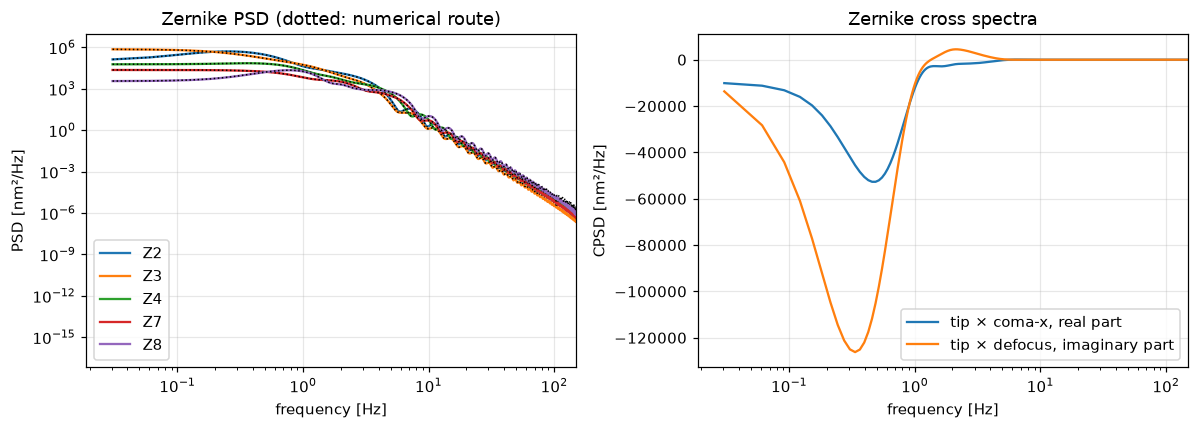

rms per mode [nm], analytic vs numerical:
  Z2:  530.4   529.2
  Z3:  530.4   529.4
  Z4:  263.8   264.2
  Z7:  153.4   153.6
  Z8:  153.4   153.6


In [5]:
def zernike_ft(js):
    nm = [noll_nm(j) for j in js]
    def resp(fx, fy, l=None):
        f = np.maximum(np.hypot(fx, fy), 1e-12); t = np.arctan2(fy, fx)
        out = []
        for n, m in nm:
            a = abs(m)
            ang = 1.0 if m == 0 else np.sqrt(2) * (np.cos(a * t) if m > 0 else np.sin(a * t))
            out.append(np.sqrt(n + 1) * 2 * jv(n + 1, np.pi * D * f) / (np.pi * D * f) * (-1) ** a * 1j ** n * ang)
        return np.stack(out, 1)
    return resp

js = [2, 3, 4, 7, 8]                         # tip (x), tilt (y), defocus, coma (y), coma (x)
z_num = fourier_response(zern[np.array(js) - 2])
nu, Pz  = one_sided(spectra(zernike_ft(js)))
_,  Pzn = one_sided(spectra(lambda fx, fy, l: z_num(fx, fy)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, j in enumerate(js):
    ax[0].loglog(nu[1:], Pz[1:, k, k].real, label=f'Z{j}')
    ax[0].loglog(nu[1:], Pzn[1:, k, k].real, 'k:', lw=1)
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD [nm²/Hz]', title='Zernike PSD (dotted: numerical route)')
ax[0].legend()
ax[1].semilogx(nu[1:], Pz[1:, 0, 4].real, label='tip × coma-x, real part')
ax[1].semilogx(nu[1:], Pz[1:, 0, 2].imag, label='tip × defocus, imaginary part')
ax[1].set(xlabel='frequency [Hz]', ylabel='CPSD [nm²/Hz]', title='Zernike cross spectra')
ax[1].legend(); [a.set_xlim(right=nu_ok) for a in ax]; plt.tight_layout(); plt.show()

print('rms per mode [nm], analytic vs numerical:')
for k, j in enumerate(js):
    print(f'  Z{j}: {np.sqrt(Pz[:, k, k].real.sum() * dnu):6.1f}  {np.sqrt(Pzn[:, k, k].real.sum() * dnu):6.1f}')

A real cross spectrum (tip × coma) means the two modes are correlated at zero time lag; an imaginary one
(tip × defocus) means they are uncorrelated at the same instant but correlated with a delay — the signature of
the wind carrying the same turbulence across the pupil. This delayed correlation is what a joint predictor exploits.

**KL modes**: same engine, numerical maps.

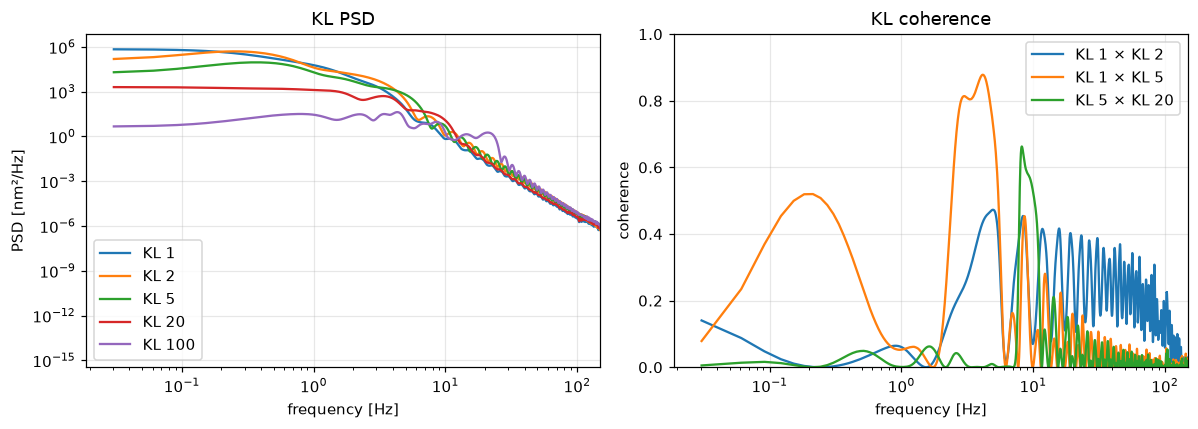

In [6]:
sel = [0, 1, 4, 19, 99]                      # KL modes to look at (0 = first mode)
kl_resp = fourier_response(kl[sel])
nu, Pk = one_sided(spectra(lambda fx, fy, l: kl_resp(fx, fy)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, i in enumerate(sel):
    ax[0].loglog(nu[1:], Pk[1:, k, k].real, label=f'KL {i + 1}')
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD [nm²/Hz]', title='KL PSD'); ax[0].legend()
for a, b in [(0, 1), (0, 2), (2, 3)]:
    ax[1].semilogx(nu[1:], coherence(Pk, a, b)[1:], label=f'KL {sel[a] + 1} × KL {sel[b] + 1}')
ax[1].set(xlabel='frequency [Hz]', ylabel='coherence', title='KL coherence', ylim=(0, 1)); ax[1].legend()
[a.set_xlim(right=nu_ok) for a in ax]; plt.tight_layout(); plt.show()

## 5. Pyramid aliasing
The pyramid (project file `pyramid.py`, unmodulated, linearised around a flat wavefront) and the reconstructor
$R=\mathrm{IM}^+$ of the first `n_corr` KL modes give, for each mode, a measurement map $M_j$ such that the
measured coefficient is $m_j=\sum M_j\varphi/N_{pix}$. If the controlled modes were perfectly corrected, what
remains in the measurement is the **aliasing**:
$$a^{alias}_j=\sum (M_j-K_j)\,\varphi/N_{pix},$$
with $K_j$ the KL map. $M_j-K_j$ is blind to the controlled modes, so only the uncorrected high spatial frequencies
leak in. Its spectrum, and its cross spectrum with the true modes, come from the same engine.

Limits: linear pyramid (optical gain 1, which overestimates aliasing compared with a real, saturating pyramid),
frozen flow, and spatial frequencies above `fmax` = simulation-grid Nyquist are ignored. The aliasing level depends
on `os_` (pyramid sampling and frequency range): check that it has converged by increasing `os_`.

check: reconstructor on its own modes (should be ~0): 1.3594928438483207e-15


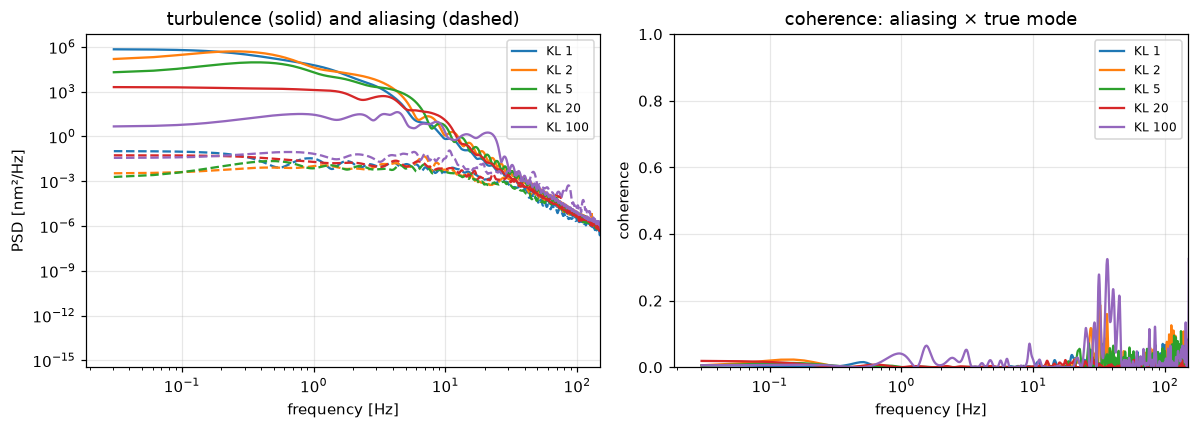

KL    1: turbulence   535.4 nm   aliasing  0.43 nm
KL    2: turbulence   535.3 nm   aliasing  0.43 nm
KL    5: turbulence   269.4 nm   aliasing  0.34 nm
KL   20: turbulence    61.3 nm   aliasing  0.47 nm
KL  100: turbulence    13.1 nm   aliasing  0.88 nm


In [7]:
from pyramid import Pyramid
k_wfs = 2 * np.pi / (lam_wfs * 1e9)          # rad per nm at the WFS wavelength
pyr = Pyramid(n_pup, os_)
img = np.zeros((n_pup, n_pup))
IM = []
for mode in kl:
    img[pupil] = mode * k_wfs
    IM.append(pyr.signal_lin(img))
IM = np.array(IM).T                          # signals x modes
Rec = np.linalg.pinv(IM)                     # modes x signals
meas = np.array([k_wfs * pyr.signal_lin_T(Rec[i])[pupil] for i in sel]) * npix   # measurement maps M_j
alias = meas - kl[sel]
print('check: reconstructor on its own modes (should be ~0):', np.abs(meas @ kl.T / npix - np.eye(n_corr)[sel]).max())

two = fourier_response(np.concatenate([kl[sel], alias]))
nu, Pa = one_sided(spectra(lambda fx, fy, l: two(fx, fy)))
K = len(sel)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, i in enumerate(sel):
    l, = ax[0].loglog(nu[1:], Pk[1:, k, k].real, label=f'KL {i + 1}')
    ax[0].loglog(nu[1:], Pa[1:, K + k, K + k].real, '--', color=l.get_color())
    ax[1].semilogx(nu[1:], coherence(Pa, k, K + k)[1:], label=f'KL {i + 1}')
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD [nm²/Hz]', title='turbulence (solid) and aliasing (dashed)')
ax[0].legend(fontsize=8)
ax[1].set(xlabel='frequency [Hz]', ylabel='coherence', title='coherence: aliasing × true mode', ylim=(0, 1))
ax[1].legend(fontsize=8); [a.set_xlim(right=nu_ok) for a in ax]; plt.tight_layout(); plt.show()
for k, i in enumerate(sel):
    print(f'KL {i + 1:4d}: turbulence {np.sqrt(Pk[:, k, k].real.sum() * dnu):7.1f} nm   '
          f'aliasing {np.sqrt(Pa[:, K + k, K + k].real.sum() * dnu):5.2f} nm')

## 6. Scintillation
A layer at altitude $h$ (along the line of sight), seen after Fresnel propagation (weak turbulence, Rytov
regime), splits each spatial frequency of its phase into a pupil phase and a log-amplitude $\chi$
(Roddier 1981; Ogane et al. 2021 Eq. 2):
$$\tilde\varphi_{pupil}=\cos(\pi\lambda h f^2)\,\tilde\varphi_l,\qquad \tilde\chi=\sin(\pi\lambda h f^2)\,\tilde\varphi_l .$$
So the engine is used with layer-dependent maps: $\tilde K_j\sin(\cdot)$ for $\chi$ projected on mode $j$, and
$\tilde K_j\cos(\cdot)$ for the phase on the same mode. $\chi$ is expressed in nm ($\chi\lambda/2\pi$) so that it
compares directly with the phase; intensity fluctuations are $\delta I/I\approx 2\chi$.

The pyramid also responds to amplitude: its linear response to $\chi$ gives a second measurement map $M^{\chi}_j$,
and the scintillation error on the measured mode is $\tilde M^{\chi}_j\sin(\cdot)$.
Monochromatic (`lam_wfs`); valid while the scintillation index stays below about 0.3.

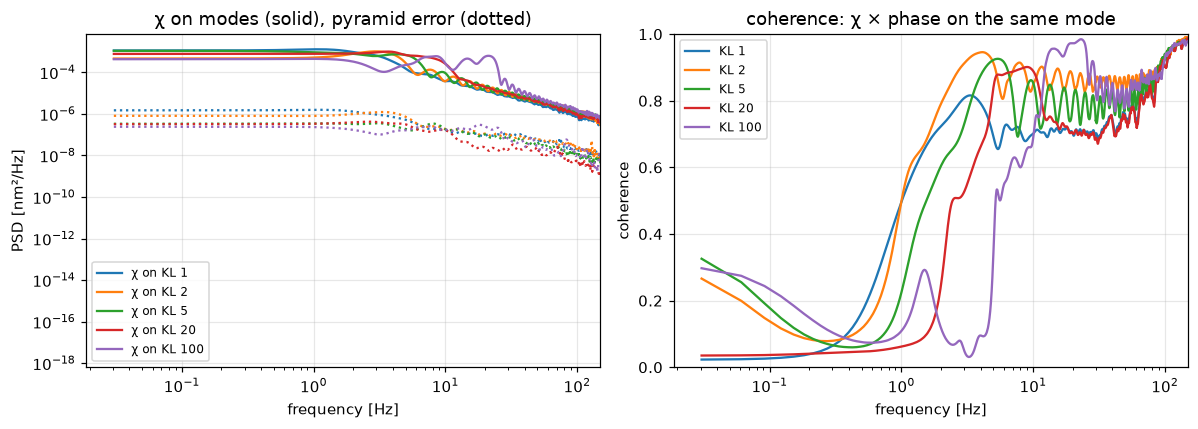

KL    1: chi  0.069 nm   pyramid scintillation error  0.004 nm
KL    2: chi  0.069 nm   pyramid scintillation error  0.004 nm
KL    5: chi  0.076 nm   pyramid scintillation error  0.003 nm
KL   20: chi  0.088 nm   pyramid scintillation error  0.002 nm
KL  100: chi  0.100 nm   pyramid scintillation error  0.003 nm


In [8]:
def amp_T(s):
    # adjoint of the pyramid's linear response to log-amplitude (same as signal_lin_T, real part instead of imaginary)
    g = pyr._FH(pyr._bin_T(s) / pyr.norm * pyr.A0)
    return pyr.P * 2 * np.real(pyr._crop(g))

meas_chi = np.array([k_wfs * amp_T(Rec[i])[pupil] for i in sel]) * npix   # measured mode per nm of chi
three = fourier_response(np.concatenate([kl[sel], meas_chi]))
lam_m = lam_wfs

def scint_resp(fx, fy, l):
    x = np.pi * lam_m * alt[l] * (fx ** 2 + fy ** 2)
    G = three(fx, fy)
    c, s = np.cos(x)[:, None], np.sin(x)[:, None]
    return np.concatenate([G[:, :K] * c, G[:, :K] * s, G[:, K:] * s], 1)   # phase, chi, pyramid error

nu, Ps = one_sided(spectra(scint_resp))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, i in enumerate(sel):
    l, = ax[0].loglog(nu[1:], Ps[1:, K + k, K + k].real, label=f'χ on KL {i + 1}')
    ax[0].loglog(nu[1:], Ps[1:, 2 * K + k, 2 * K + k].real, ':', color=l.get_color())
    ax[1].semilogx(nu[1:], coherence(Ps, k, K + k)[1:], label=f'KL {i + 1}')
ax[0].set(xlabel='frequency [Hz]', ylabel='PSD [nm²/Hz]', title='χ on modes (solid), pyramid error (dotted)')
ax[0].legend(fontsize=8)
ax[1].set(xlabel='frequency [Hz]', ylabel='coherence', title='coherence: χ × phase on the same mode', ylim=(0, 1))
ax[1].legend(fontsize=8); [a.set_xlim(right=nu_ok) for a in ax]; plt.tight_layout(); plt.show()
for k, i in enumerate(sel):
    print(f'KL {i + 1:4d}: chi {np.sqrt(Ps[:, K + k, K + k].real.sum() * dnu):6.3f} nm   '
          f'pyramid scintillation error {np.sqrt(Ps[:, 2 * K + k, 2 * K + k].real.sum() * dnu):6.3f} nm')

## 7. Using the results
`P[:, i, j]` is the one-sided cross spectrum between channels `i` and `j` on the frequency grid `nu`
(nm²/Hz, variance = `P.real.sum() * dnu`). Time-lag covariances, needed by a Wiener/VAR predictor, are its inverse
Fourier transform. To add a quantity, write its pupil weighting map and pass it to `fourier_response`; nothing
else changes.

**References.** Conan, Rousset & Madec 1995, JOSA A 12, 1559. Plantet, Carlà, Agapito & Busoni 2022, JOSA A
(arXiv:2209.00931). Noll 1976, JOSA 66, 207. Roddier 1981, Prog. Opt. 19, 281. Ogane et al. 2021, MNRAS (arXiv:2101.04294).